# Когортный анализ клиентов E-commerce (Retention & LTV)

**Цель:** Построить матрицу удержания клиентов (Retention) и проанализировать ценность когорт (LTV).

**Инструменты:** SQL (DuckDB), Python (Pandas, NumPy, Matplotlib, Seaborn).

**Данные:** События интернет-магазина (датасет с Kaggle).

In [11]:
import pandas as pd
import duckdb

# Загрузка данных и создание базы
df = pd.read_csv('user_events_ecommerce_product_analytics.csv')
con = duckdb.connect()
con.execute("CREATE TABLE events AS SELECT * FROM df")

print("База данных готова. Количество строк:")
print(con.execute("SELECT COUNT(*) FROM events").fetchall())

База данных готова. Количество строк:
[(320000,)]


In [12]:
# Находим месяц первой покупки (когорту) для каждого клиента
query_cohorts = """
    SELECT 
        user_id, 
        DATE_TRUNC('month', MIN(event_date::date)) AS cohort 
    FROM events 
    WHERE event_type = 'purchase' 
    GROUP BY user_id
"""

df_cohorts = con.execute(query_cohorts).fetchdf()
print(df_cohorts.head())

   user_id     cohort
0  U100093 2024-09-01
1  U106166 2024-04-01
2  U101223 2024-01-01
3  U108085 2024-09-01
4  U104538 2024-05-01


**Вывод по когортам:**
Успешно рассчитан месяц первой покупки (`cohort`) для каждого уникального клиента. Эти данные станут базой для расчета матрицы удержания (Retention).

In [13]:
# Загружаем таблицу когорт обратно в базу данных
con.execute("CREATE TABLE cohorts AS SELECT * FROM df_cohorts")

# Считаем разницу в месяцах между покупкой и когортой
query_diff = """
    SELECT 
        e.user_id, 
        c.cohort, 
        (EXTRACT(YEAR FROM e.event_date::date) - EXTRACT(YEAR FROM c.cohort)) * 12 + 
        (EXTRACT(MONTH FROM e.event_date::date) - EXTRACT(MONTH FROM c.cohort)) AS month_diff
    FROM events e
    JOIN cohorts c ON e.user_id = c.user_id
    WHERE e.event_type = 'purchase'
"""

df_diff = con.execute(query_diff).fetchdf()
print(df_diff.head())

   user_id     cohort  month_diff
0  U110729 2024-05-01           0
1  U103165 2024-09-01           0
2  U103436 2024-03-01           8
3  U107336 2024-03-01           0
4  U103870 2024-12-01           0


**Вывод по расчету разницы:**
Для каждой покупки рассчитано количество месяцев (`month_diff`), прошедших с момента первой покупки клиента. Значение `0` означает покупку в месяц прихода, `1` — возврат через месяц и т.д. Эти данные готовы для агрегации в итоговую матрицу.

In [14]:
# Строим итоговую матрицу удержания с помощью SQL (FILTER)
query_retention = """
    SELECT 
        cohort, 
        COUNT(DISTINCT user_id) AS total_users,
        COUNT(DISTINCT user_id) FILTER (WHERE month_diff = 0) AS m0,
        COUNT(DISTINCT user_id) FILTER (WHERE month_diff = 1) AS m1,
        COUNT(DISTINCT user_id) FILTER (WHERE month_diff = 2) AS m2,
        COUNT(DISTINCT user_id) FILTER (WHERE month_diff = 3) AS m3
    FROM df_diff 
    GROUP BY cohort
    ORDER BY cohort
"""

# Выгружаем результат в Pandas, чтобы посмотреть
df_retention = con.execute(query_retention).fetchdf()
print(df_retention)

       cohort  total_users    m0   m1   m2   m3
0  2024-01-01         1963  1963  280  300  309
1  2024-02-01         1541  1541  254  257  270
2  2024-03-01         1384  1384  228  237  218
3  2024-04-01         1233  1233  208  189  201
4  2024-05-01          924   924  157  144  160
5  2024-06-01          816   816  143  123  119
6  2024-07-01          668   668   95  119  113
7  2024-08-01          536   536   69   93   93
8  2024-09-01          506   506   73   81   78
9  2024-10-01          408   408   66   57    0
10 2024-11-01          319   319   53    0    0
11 2024-12-01          268   268    0    0    0


**Вывод по матрице удержания (SQL):**
С помощью одного SQL-запроса (с использованием функции `FILTER`) была построена матрица удержания клиентов (Retention). 

Из данных видно, что пик привлечения пришелся на январь 2024 года (1963 клиента). Однако уже через месяц из этой когорты вернулось только 280 человек (~14% удержания). 
Сравнивая когорты между собой, можно заметить, что удержание на второй месяц (`m2`) у клиентов, пришедших в феврале (257 чел.), выше, чем в январе (300 чел. при меньшем общем числе). Это требует более детального процентного анализа в Pandas.

In [15]:
# Переводим абсолютные значения в проценты
# Делим колонки m0, m1, m2, m3 на total_users и умножаем на 100
df_pct = df_retention[['cohort', 'm0', 'm1', 'm2', 'm3']].copy()

df_pct[['m0', 'm1', 'm2', 'm3']] = (df_pct[['m0', 'm1', 'm2', 'm3']].div(df_retention['total_users'], axis=0) * 100).round(1)

print(df_pct)

       cohort     m0    m1    m2    m3
0  2024-01-01  100.0  14.3  15.3  15.7
1  2024-02-01  100.0  16.5  16.7  17.5
2  2024-03-01  100.0  16.5  17.1  15.8
3  2024-04-01  100.0  16.9  15.3  16.3
4  2024-05-01  100.0  17.0  15.6  17.3
5  2024-06-01  100.0  17.5  15.1  14.6
6  2024-07-01  100.0  14.2  17.8  16.9
7  2024-08-01  100.0  12.9  17.4  17.4
8  2024-09-01  100.0  14.4  16.0  15.4
9  2024-10-01  100.0  16.2  14.0   0.0
10 2024-11-01  100.0  16.6   0.0   0.0
11 2024-12-01  100.0   0.0   0.0   0.0


**Вывод по процентному анализу когорт:**
После перевода абсолютных значений в проценты, мы можем сравнить качество удержания разных когорт. 
Анализ показал, что удержание на первый месяц (`m1`) росло с января (14.3%) и достигло пика для когорт мая-июня (17.0% и 17.5%). Однако начиная с июльской когорты наблюдается резкое падение удержания (до 14.2%, а в августе — до 12.9%). 

Также интересной особенностью январской когорты является рост возвратов от месяца к месяцу (с 14.3% в `m1` до 15.7% в `m3`), что может указывать на сезонный фактор или успешные реактивационные кампании весной.

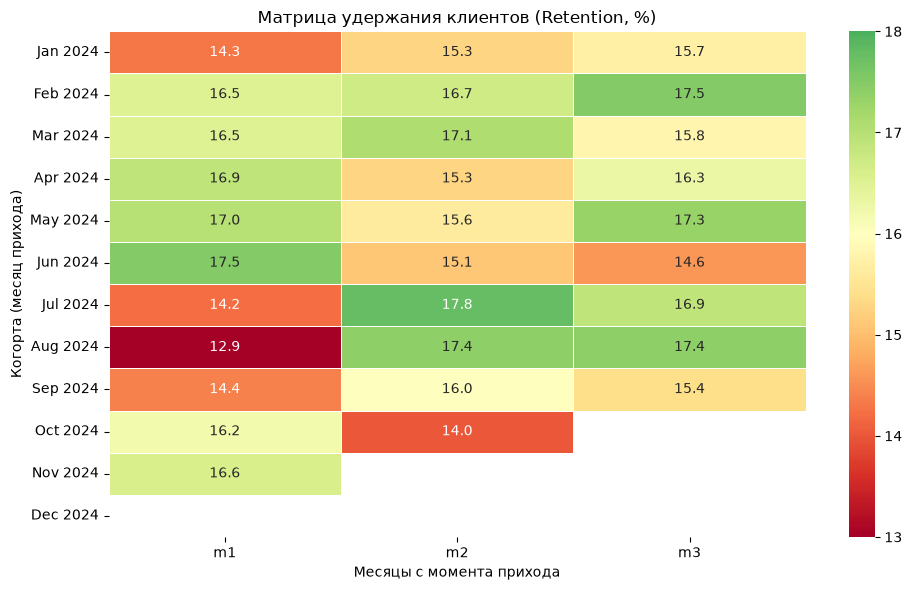

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Подготовка данных для тепловой карты
df_heatmap = df_pct.copy()
df_heatmap['cohort'] = df_heatmap['cohort'].dt.strftime('%b %Y')
df_heatmap = df_heatmap.set_index('cohort')

# Оставляем только целевые месяцы удержания и заменяем нули будущих периодов на NaN
heatmap_data = df_heatmap[['m1', 'm2', 'm3']].replace(0, np.nan)

# Построение тепловой карты
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_data, 
    annot=True, 
    cmap='RdYlGn', 
    fmt='.1f', 
    linewidths=0.5, 
    vmin=13, 
    vmax=18, 
    center=16
)

plt.title('Матрица удержания клиентов (Retention, %)')
plt.ylabel('Когорта (месяц прихода)')
plt.xlabel('Месяцы с момента прихода')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Вывод по визуализации:** Тепловая карта наглядно демонстрирует динамику удержания клиентов. Наблюдается четкий тренд: когорты конца зимы, весны и начала лета (**февраль–июнь**) показывают наиболее стабильное удержание на первый месяц (зеленая зона, ~16.5–17.5%).

Однако начиная с июльской когорты происходит резкое падение показателя (до 14.2% в июле и 12.9% в августе — красная зона).

**Рекомендация:** Инициировать проверку маркетинговых кампаний и технического состояния продукта в июле–августе, так как клиенты, привлеченные в этот период, возвращаются значительно реже.

___

### Анализ LTV по когортам (Cumulative ARPU)

Мы выяснили, как меняется доля возвращающихся клиентов. Однако для бизнеса не менее важно понимать, какую финансовую ценность приносит каждый привлеченный пользователь с течением времени.

Чтобы корректно сравнить когорты разного размера, рассчитаем **накопительный LTV на одного клиента (Cumulative ARPU)** — суммарный доход, который в среднем приносит один покупатель за первый месяц (`m0`) и последующие 3 месяца жизни (`m1` – `m3`). Это покажет реальную окупаемость привлечения и динамику монетизации разных когорт.

=== Накопительный LTV на одного клиента ===
          LTV m0  LTV m1  LTV m2  LTV m3
cohort                                  
Jan 2024  3098.8  3558.4  4048.0  4539.2
Feb 2024  3042.7  3577.3  4088.3  4627.6
Mar 2024  3153.9  3666.2  4181.2  4689.7
Apr 2024  3151.3  3662.2  4142.8  4644.9
May 2024  3055.5  3589.4  4045.4  4573.2
Jun 2024  3083.5  3625.2  4076.5  4541.5
Jul 2024  3079.9  3520.1  4055.9  4577.2
Aug 2024  3139.8  3544.0  4066.2  4606.4
Sep 2024  3054.6  3526.2  4015.0  4506.4
Oct 2024  2992.0  3513.5  3942.8     NaN
Nov 2024  2984.7  3505.2     NaN     NaN
Dec 2024  3148.8     NaN     NaN     NaN


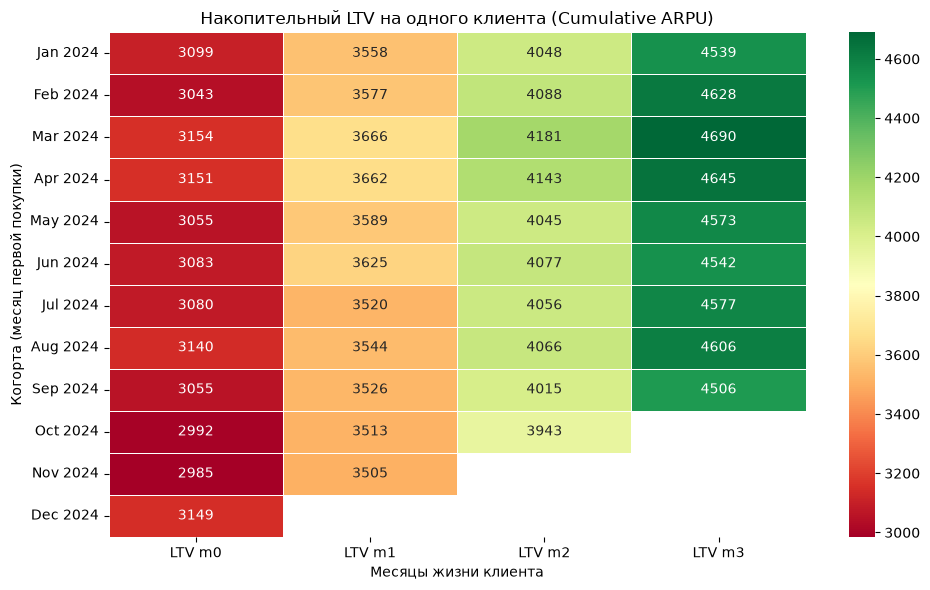

In [21]:
# Расчет общей выручки по когортам
query_ltv = """
SELECT 
    c.cohort,
    SUM(e.price) FILTER (
        WHERE (EXTRACT(YEAR FROM e.event_date::date) - EXTRACT(YEAR FROM c.cohort)) * 12 
            + (EXTRACT(MONTH FROM e.event_date::date) - EXTRACT(MONTH FROM c.cohort)) = 0
    ) AS rev_m0,
    SUM(e.price) FILTER (
        WHERE (EXTRACT(YEAR FROM e.event_date::date) - EXTRACT(YEAR FROM c.cohort)) * 12 
            + (EXTRACT(MONTH FROM e.event_date::date) - EXTRACT(MONTH FROM c.cohort)) = 1
    ) AS rev_m1,
    SUM(e.price) FILTER (
        WHERE (EXTRACT(YEAR FROM e.event_date::date) - EXTRACT(YEAR FROM c.cohort)) * 12 
            + (EXTRACT(MONTH FROM e.event_date::date) - EXTRACT(MONTH FROM c.cohort)) = 2
    ) AS rev_m2,
    SUM(e.price) FILTER (
        WHERE (EXTRACT(YEAR FROM e.event_date::date) - EXTRACT(YEAR FROM c.cohort)) * 12 
            + (EXTRACT(MONTH FROM e.event_date::date) - EXTRACT(MONTH FROM c.cohort)) = 3
    ) AS rev_m3
FROM events e
JOIN cohorts c ON e.user_id = c.user_id
WHERE e.event_type = 'purchase'
GROUP BY c.cohort
ORDER BY c.cohort
"""

df_rev = con.execute(query_ltv).fetchdf()

# Привязываем таблицы к индексу когорты для безопасного деления
df_rev_idx = df_rev.set_index('cohort')
users_idx = df_retention.set_index('cohort')['total_users']

# Расчет накопительного LTV на одного пользователя (Cumulative ARPU)
arpu_cols = ['rev_m0', 'rev_m1', 'rev_m2', 'rev_m3']
df_arpu = df_rev_idx[arpu_cols].div(users_idx, axis=0)

df_ltv_cum = df_arpu.cumsum(axis=1, skipna=False)
df_ltv_cum.columns = ['LTV m0', 'LTV m1', 'LTV m2', 'LTV m3']
df_ltv_cum.index = df_ltv_cum.index.strftime('%b %Y')

print("=== Накопительный LTV на одного клиента ===")
print(df_ltv_cum.round(1))

# Визуализация тепловой карты LTV
plt.figure(figsize=(10, 6))
sns.heatmap(
    df_ltv_cum, 
    annot=True, 
    fmt='.0f', 
    cmap='RdYlGn', 
    linewidths=0.5
)

plt.title('Накопительный LTV на одного клиента (Cumulative ARPU)')
plt.ylabel('Когорта (месяц первой покупки)')
plt.xlabel('Месяцы жизни клиента')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Вывод по анализу LTV:**
Тепловая карта накопительного LTV (Cumulative ARPU) показывает стабильную монетизацию клиентов во всех когортах:
* **Базовый чек (`LTV m0`):** В месяц первой покупки один клиент в среднем приносит около **2 985 – 3 154** денежных единиц. Этот показатель остается ровным на протяжении всего года без резких просадок.
* **Рост ценности (`LTV m3`):** За три месяца жизни накопительный доход с одного клиента вырастает в среднем на **48–50%** и достигает **4 506 – 4 690** единиц (пиковое значение зафиксировано у мартовской когорты — **4 690**).
* **Компенсация оттока:** Примечательно, что летние когорты (июль — **4 577**, август — **4 606** к 3-му месяцу), несмотря на зафиксированное ранее падение процента удержания (`Retention`), по итоговому LTV не уступают весенним когортам (например, май — **4 573**, июнь — **4 542**). Это говорит о том, что хотя летом возвращалось меньше клиентов, их средний чек при повторных покупках был выше.

---

### Итоговое резюме проекта и рекомендации

1. **Масштабировать успешные практики весны:** Когорты февраля–апреля показали наилучший баланс между удержанием (`~16.5–17%` в первый месяц) и накопительной выручкой (`4 628 – 4 690` на клиента к `m3`). Рекомендуется изучить рекламные каналы и механики привлечения этого периода для масштабирования.
2. **Аудит летнего трафика:** Для июльской и августовской когорт зафиксировано падение возвратов (до `12.9%` в августе), но сохранение высокого итогового LTV (`4 577 – 4 606`). Необходимо проверить источники трафика в эти месяцы — вероятно, привлекалась более дорогая или нишевая аудитория с меньшей частотой покупок.
3. **Развитие программы лояльности:** Основной прирост LTV формируется за счет повторных заказов в `m1` – `m3` (почти половина от стартовой выручки). Внедрение триггерных рассылок или бонусов на вторую покупку в течение первых 30 дней поможет поднять конверсию в повторный заказ и увеличить итоговый LTV.
